# Notebook 9: Estacionariedad y patrones temporales del ozono en UIZ

### Análisis de la serie horaria de O₃ · Enero–febrero de 2026

Este notebook analiza la concentración horaria de ozono (O₃) registrada en la estación UIZ. Se identifican y tratan los datos faltantes, se explora la autocorrelación hasta 72 horas y se evalúa la estacionariedad mediante las pruebas ADF y KPSS.

Se comparan tres transformaciones: restar la media de cada hora del día, restar la media de cada combinación mes × hora y aplicar una diferencia de 24 horas. Finalmente, se examina cómo cambian la autocorrelación y la varianza.

**Fuente de datos:** SIMAT, Ciudad de México.  
**Archivo:** `contaminantes_2026.csv`.

In [1]:
# Si te falta alguna librería, ejecuta en otra celda:
# %pip install pandas numpy matplotlib statsmodels

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller, kpss, acf
from IPython.display import display

2. Leer los datos y seleccionar O₃ de UIZ
Tu CSV tiene nueve líneas de metadatos antes del encabezado, por eso utilizamos skiprows=9.

In [2]:
df = pd.read_csv(
    "contaminantes_2026.csv",
    skiprows=9,
    low_memory=False
)

df.columns = df.columns.str.strip().str.lower()

df["date"] = pd.to_datetime(df["date"], errors="raise")
df["valor"] = pd.to_numeric(df["valor"], errors="coerce")

for columna in ["id_station", "id_parameter"]:
    df[columna] = df[columna].astype("string").str.strip().str.upper()

uiz = df.loc[
    (df["id_station"] == "UIZ")
    & (df["id_parameter"] == "O3")
    & (df["date"].dt.year == 2026)
].copy()

if uiz.empty:
    raise ValueError("No se encontraron registros de O3 para UIZ.")

if uiz["date"].duplicated().any():
    raise ValueError("Hay fechas duplicadas. Revisa esos registros.")

s_registrada = (
    uiz.set_index("date")["valor"]
    .sort_index()
    .replace([np.inf, -np.inf], np.nan)
)

# Crear una cuadrícula horaria: una posición por cada hora.
s_original = s_registrada.asfreq("h")
s_original.name = "O3_UIZ"

print("Inicio:", s_original.index.min())
print("Fin:", s_original.index.max())
print("Horas esperadas:", len(s_original))

display(s_original.head())

Inicio: 2026-01-01 00:00:00
Fin: 2026-02-28 23:00:00
Horas esperadas: 1416


date
2026-01-01 00:00:00    14.0
2026-01-01 01:00:00     5.0
2026-01-01 02:00:00     2.0
2026-01-01 03:00:00     3.0
2026-01-01 04:00:00     3.0
Freq: h, Name: O3_UIZ, dtype: float64

Explicación: dejamos la fecha como índice y la concentración como valor. asfreq("h") hace explícitas las horas ausentes.
Esto es importante porque un rezago de 24 posiciones debe representar exactamente 24 horas.

3. Inciso a: contar los faltantes y los huecos consecutivos
Conviene distinguir entre horas faltantes y huecos. Por ejemplo, cinco horas seguidas sin medición constituyen un hueco de cinco horas.

In [3]:
faltante = s_original.isna()

# Cada cambio entre dato disponible y faltante inicia un grupo.
grupos = faltante.ne(faltante.shift()).cumsum()

registro = pd.DataFrame({
    "fecha": s_original.index,
    "grupo": grupos.to_numpy(),
    "faltante": faltante.to_numpy()
})

huecos = (
    registro.loc[registro["faltante"]]
    .groupby("grupo")
    .agg(
        inicio=("fecha", "min"),
        fin=("fecha", "max"),
        horas=("fecha", "size")
    )
    .reset_index(drop=True)
)

resumen_faltantes = pd.Series({
    "horas_esperadas": len(s_original),
    "horas_con_dato": s_original.notna().sum(),
    "horas_faltantes": faltante.sum(),
    "porcentaje_faltante": 100 * faltante.mean(),
    "numero_de_huecos": len(huecos),
    "hueco_mas_largo_h": (
        int(huecos["horas"].max()) if not huecos.empty else 0
    ),
    "horas_sin_fila_en_csv": len(s_original) - len(s_registrada)
})

display(resumen_faltantes)
display(huecos.sort_values("horas", ascending=False))

horas_esperadas          1416.000000
horas_con_dato           1291.000000
horas_faltantes           125.000000
porcentaje_faltante         8.827684
numero_de_huecos           34.000000
hueco_mas_largo_h          20.000000
horas_sin_fila_en_csv       0.000000
dtype: float64

,inicio,fin,horas
19,2026-02-06 18:00:00,2026-02-07 13:00:00,20
21,2026-02-07 18:00:00,2026-02-08 07:00:00,14
28,2026-02-18 18:00:00,2026-02-19 07:00:00,14
3,2026-01-05 23:00:00,2026-01-06 07:00:00,9
13,2026-01-28 00:00:00,2026-01-28 07:00:00,8
27,2026-02-16 23:00:00,2026-02-17 03:00:00,5
23,2026-02-10 23:00:00,2026-02-11 02:00:00,4
18,2026-02-04 23:00:00,2026-02-05 02:00:00,4
16,2026-01-30 12:00:00,2026-01-30 15:00:00,4
15,2026-01-29 23:00:00,2026-01-30 02:00:00,4


Se va a interpolar los huecos interiores de hasta 24 horas y recortar los faltantes de los extremos. Es una decisión exploratoria para analizar ambos meses; los valores interpolados pueden suavizar la variabilidad y modificar la ACF.

In [4]:
MAX_HUECO_H = 24

if not huecos.empty and huecos["horas"].max() > MAX_HUECO_H:
    raise ValueError(
        "Hay huecos mayores a 24 horas. "
        "Revisa el tratamiento antes de continuar."
    )

# Interpolación entre mediciones disponibles.
# No extrapolar los extremos.
s_interpolada = s_original.interpolate(
    method="time",
    limit_area="inside"
)

# Recortar únicamente los extremos que siguen sin dato.
s = s_interpolada.loc[
    s_interpolada.first_valid_index():
    s_interpolada.last_valid_index()
].copy()

if s.isna().any():
    raise ValueError("Todavía quedan faltantes dentro de la serie.")

imputados = s_original.reindex(s.index).isna()

print("Horas interpoladas:", imputados.sum())
print("Horas recortadas:", len(s_original) - len(s))
print("Horas para el análisis:", len(s))

Horas interpoladas: 124
Horas recortadas: 1
Horas para el análisis: 1415


Se identificaron 125 horas faltantes (8.83%), distribuidas en 34 huecos. Se aplicó interpolación temporal a los huecos interiores, cuya duración máxima fue de 20 horas, y se eliminó el faltante del extremo final. Este tratamiento conserva la continuidad horaria, pero puede suavizar la serie; los resultados se interpretan considerando esa limitación.

4. Inciso b: graficar la serie y su ACF hasta 72 horas

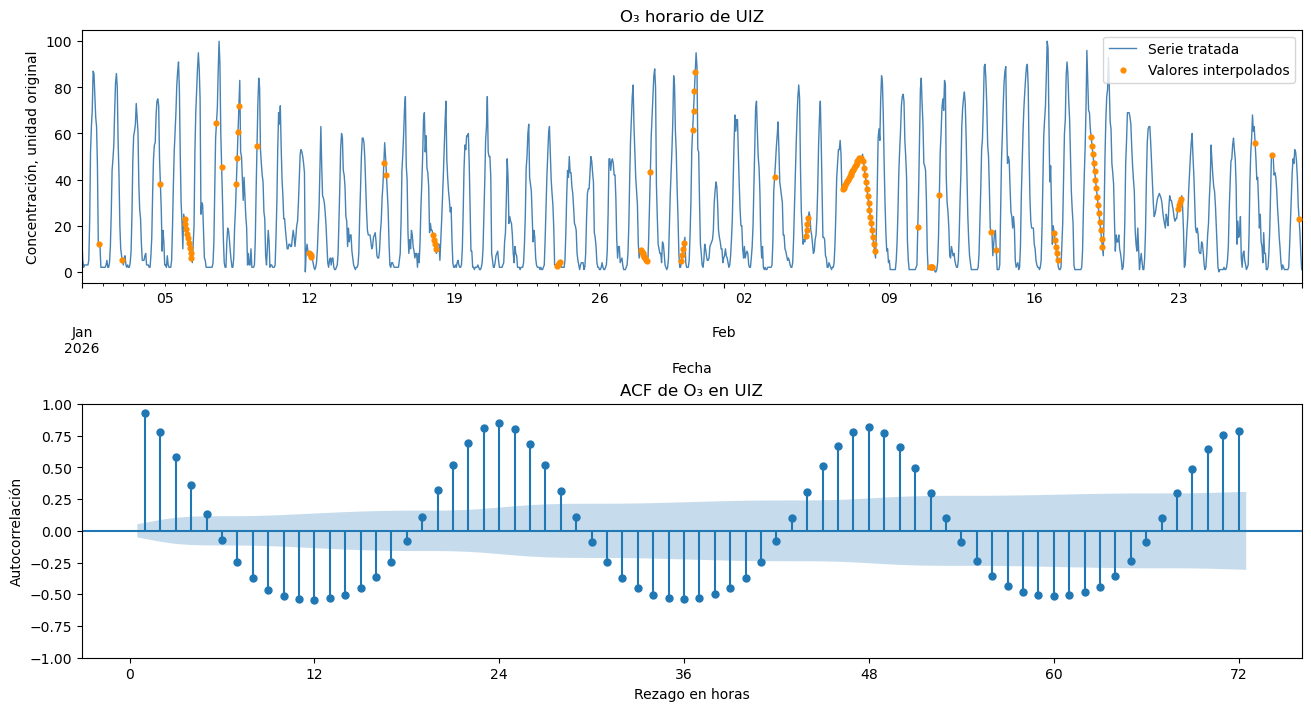

In [5]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 7),
    constrained_layout=True
)

s.plot(
    ax=axes[0],
    color="steelblue",
    linewidth=1,
    label="Serie tratada"
)

axes[0].scatter(
    s.index[imputados],
    s.loc[imputados],
    color="darkorange",
    s=12,
    label="Valores interpolados",
    zorder=3
)

axes[0].set(
    title="O₃ horario de UIZ",
    xlabel="Fecha",
    ylabel="Concentración, unidad original"
)
axes[0].legend()

plot_acf(
    s,
    lags=72,
    zero=False,
    fft=True,
    ax=axes[1]
)

axes[1].set(
    title="ACF de O₃ en UIZ",
    xlabel="Rezago en horas",
    ylabel="Autocorrelación"
)
axes[1].set_xticks(np.arange(0, 73, 12))

plt.show()

La ACF muestra cuánto se relaciona la serie con sus valores anteriores. Por ejemplo:
- El rezago 1 compara valores separados por una hora.
- El rezago 24 compara valores separados por un día.
- Los rezagos 48 y 72 comparan valores separados por dos y tres días.
Si aparecen picos en 24, 48 y 72 horas, hay evidencia descriptiva de un patrón diario.

Inciso c: ejecutar ADF y KPSS
Las pruebas tienen hipótesis nulas diferentes:
Prueba	Hipótesis nula	Si p < 0.05
ADF	La serie tiene raíz unitaria	Se rechaza la raíz unitaria
KPSS	La serie es estacionaria alrededor de una constante	Se rechaza la estacionariedad


Por eso, ADF con p pequeño y KPSS con p grande ofrece resultados compatibles con estacionariedad. Esto no constituye una demostración definitiva. ADF, KPSS.
Crearemos una función para repetir las pruebas con los mismos parámetros.

In [6]:
def pruebas_estacionariedad(serie, nombre):
    if serie.isna().any():
        raise ValueError("La serie contiene faltantes.")

    adf = adfuller(
        serie,
        regression="c",
        maxlag=48,
        autolag="AIC"
    )

    resultado_kpss = kpss(
        serie,
        regression="c",
        nlags="auto"
    )

    p_adf = adf[1]
    p_kpss = resultado_kpss[1]

    if p_adf < 0.05 and p_kpss >= 0.05:
        lectura = "Compatible con estacionariedad"
    elif p_adf >= 0.05 and p_kpss < 0.05:
        lectura = "Evidencia contra estacionariedad"
    elif p_adf < 0.05 and p_kpss < 0.05:
        lectura = "Resultados discordantes"
    else:
        lectura = "Resultado inconcluso"

    return pd.DataFrame([{
        "serie": nombre,
        "n": len(serie),
        "ADF_estadistico": adf[0],
        "ADF_p": p_adf,
        "ADF_rezagos": adf[2],
        "KPSS_estadistico": resultado_kpss[0],
        "KPSS_p": p_kpss,
        "KPSS_rezagos": resultado_kpss[2],
        "lectura": lectura
    }]).set_index("serie")


resultado_c = pruebas_estacionariedad(
    s,
    "c) Original tratada"
)

display(resultado_c)

,n,ADF_estadistico,ADF_p,ADF_rezagos,KPSS_estadistico,KPSS_p,KPSS_rezagos,lectura
serie,,,,,,,,
c) Original tratada,1415,-2.752665,0.06536,48,0.638709,0.019117,19,Evidencia contra estacionariedad


Regression="c" incluye una constante. En ADF permitimos hasta 48 rezagos para incorporar dependencia de hasta dos días; AIC selecciona cuántos utilizar.
KPSS puede mostrar InterpolationWarning: su tabla limita los valores p entre 0.01 y 0.10. Cuando aparece la advertencia, esos extremos representan límites, no valores p exactos.

6. Inciso d: restar la media de cada hora del día
Para cada hora calculamos su concentración promedio. Después, a cada observación le restamos el promedio de su hora:
\[
r_t^{(h)}=y_t-\overline{y}_{h(t)}
\]

In [7]:
media_por_hora = s.groupby(s.index.hour).mean()

media_hora_en_cada_fila = (
    s.groupby(s.index.hour).transform("mean")
)

s_hora = s - media_hora_en_cada_fila

resultado_d = pruebas_estacionariedad(
    s_hora,
    "d) Sin media por hora"
)

display(media_por_hora.rename("media_O3").to_frame())
display(resultado_d)

/var/folders/q8/8kzzlcj12tqbxzmkf31wng_80000gn/T/ipykernel_14711/3878245278.py:12: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  resultado_kpss = kpss(


,media_O3
date,
0,9.723164
1,8.975383
2,8.769976
3,8.140839
4,6.933737
5,5.167312
6,4.070379
7,3.956497
8,6.808717


,n,ADF_estadistico,ADF_p,ADF_rezagos,KPSS_estadistico,KPSS_p,KPSS_rezagos,lectura
serie,,,,,,,,
d) Sin media por hora,1415,-4.125478,0.000879,21,0.788823,0.01,21,Resultados discordantes


A todas las mediciones de las 14:00 les restamos el promedio de las 14:00, independientemente del mes. Esto elimina el perfil diario promedio.
transform("mean") devuelve una serie del mismo tamaño que s, asignando a cada fecha la media que le corresponde.

7. Inciso e: restar la media de cada combinación mes × hora
Ahora permitimos que el perfil diario sea diferente en cada mes

In [8]:
media_mes_hora_en_cada_fila = (
    s.groupby([
        s.index.month,
        s.index.hour
    ]).transform("mean")
)

s_mes_hora = s - media_mes_hora_en_cada_fila

resultado_e = pruebas_estacionariedad(
    s_mes_hora,
    "e) Sin media por mes × hora"
)

# Tabla: horas en filas y meses en columnas.
perfil_mes_hora = (
    s.groupby([
        s.index.month,
        s.index.hour
    ])
    .mean()
    .unstack(level=0)
)

perfil_mes_hora.index.name = "hora"
perfil_mes_hora.columns.name = "mes"

display(perfil_mes_hora)
display(resultado_e)

/var/folders/q8/8kzzlcj12tqbxzmkf31wng_80000gn/T/ipykernel_14711/3878245278.py:12: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  resultado_kpss = kpss(


mes,1,2
hora,,
0,7.043011,12.690476
1,6.908602,11.263605
2,6.516129,11.265306
3,5.994624,10.517007
4,4.969892,9.107993
5,3.880645,6.591837
6,3.275269,4.950680
7,2.960215,5.059524
8,5.451613,8.311224


,n,ADF_estadistico,ADF_p,ADF_rezagos,KPSS_estadistico,KPSS_p,KPSS_rezagos,lectura
serie,,,,,,,,
e) Sin media por mes × hora,1415,-4.415299,0.000279,21,0.290713,0.1,20,Compatible con estacionariedad


Una observación de enero a las 14:00 se ajusta usando el promedio de enero a las 14:00. Una observación de febrero a esa hora utiliza el promedio de febrero.
Los incisos d) y e) se calculan directamente a partir de s. Así comparas dos formas distintas de retirar el patrón promedio.

8. Inciso f: diferencia de 24 horas y nuevas pruebas

In [9]:
s_diff24 = s.diff(24).iloc[24:]

resultado_f = pruebas_estacionariedad(
    s_diff24,
    "f) Diferencia de 24 h"
)

display(resultado_f)

/var/folders/q8/8kzzlcj12tqbxzmkf31wng_80000gn/T/ipykernel_14711/3878245278.py:12: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  resultado_kpss = kpss(


,n,ADF_estadistico,ADF_p,ADF_rezagos,KPSS_estadistico,KPSS_p,KPSS_rezagos,lectura
serie,,,,,,,,
f) Diferencia de 24 h,1391,-6.48384,1.275347e-08,48,0.027947,0.1,18,Compatible con estacionariedad


Explicación: diff(24) resta a cada concentración la concentración registrada 24 horas antes. Las primeras 24 posiciones quedan sin resultado porque no tienen un antecedente dentro del archivo, por eso las retiramos con .iloc[24:].
Aquí aplicamos la diferencia a la serie original tratada s, para compararla con el ajuste del inciso e).

9. Comparar la ACF y la varianza de e y f
Como la diferencia pierde las primeras 24 horas, compararemos ambos métodos sobre las mismas fechas.

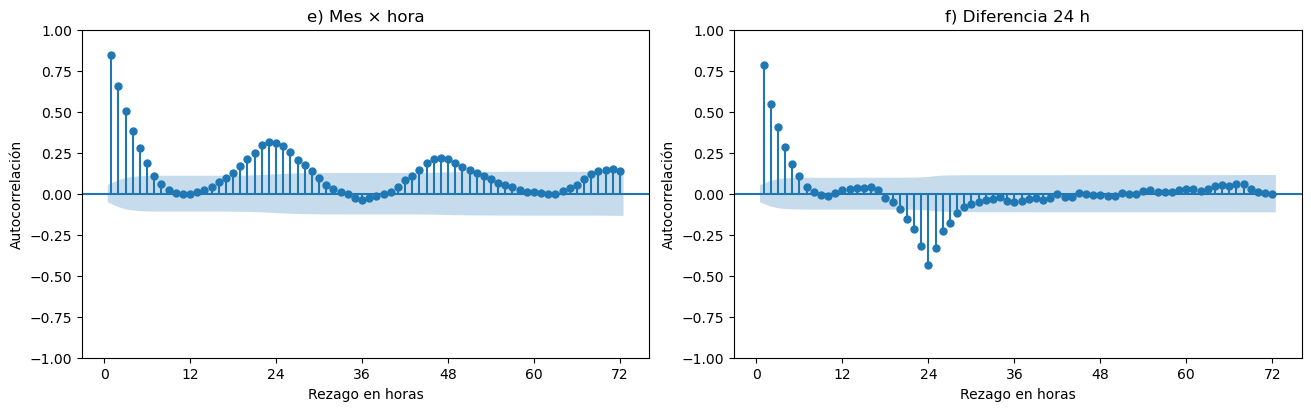

In [10]:
comparacion = pd.concat({
    "e) Mes × hora": s_mes_hora,
    "f) Diferencia 24 h": s_diff24
}, axis=1).iloc[24:]

if comparacion.isna().any().any():
    raise ValueError("Hay faltantes en el periodo de comparación.")

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4),
    constrained_layout=True
)

for ax, (nombre, serie) in zip(axes, comparacion.items()):
    plot_acf(
        serie,
        lags=72,
        zero=False,
        fft=True,
        ax=ax,
        title=nombre
    )

    ax.set(
        xlabel="Rezago en horas",
        ylabel="Autocorrelación"
    )
    ax.set_xticks(np.arange(0, 73, 12))
    ax.set_ylim(-1, 1)

plt.show()

In [11]:
filas = []

for nombre, serie in comparacion.items():
    autocorrelaciones = acf(
        serie,
        nlags=72,
        fft=True
    )

    filas.append({
        "serie": nombre,
        "n": len(serie),
        "varianza": serie.var(ddof=1),
        "ACF_24": autocorrelaciones[24],
        "ACF_48": autocorrelaciones[48],
        "ACF_72": autocorrelaciones[72]
    })

resumen_comparacion = (
    pd.DataFrame(filas)
    .set_index("serie")
)

display(resumen_comparacion.round(4))

,n,varianza,ACF_24,ACF_48,ACF_72
serie,,,,,
e) Mes × hora,1391,118.0888,0.3115,0.2113,0.1386
f) Diferencia 24 h,1391,163.3675,-0.4345,-0.0054,0.0011


var(ddof=1) calcula la varianza muestral. Una varianza menor indica menor dispersión, pero no basta para decidir qué transformación conviene: también debemos revisar las pruebas y la dependencia temporal restante.

In [12]:
resultados_pruebas = pd.concat([
    resultado_c,
    resultado_d,
    resultado_e,
    resultado_f
])

display(resultados_pruebas)

,n,ADF_estadistico,ADF_p,ADF_rezagos,KPSS_estadistico,KPSS_p,KPSS_rezagos,lectura
serie,,,,,,,,
c) Original tratada,1415,-2.752665,6.535977e-02,48,0.638709,0.019117,19,Evidencia contra estacionariedad
d) Sin media por hora,1415,-4.125478,8.787530e-04,21,0.788823,0.010000,21,Resultados discordantes
e) Sin media por mes × hora,1415,-4.415299,2.788638e-04,21,0.290713,0.100000,20,Compatible con estacionariedad
f) Diferencia de 24 h,1391,-6.483840,1.275347e-08,48,0.027947,0.100000,18,Compatible con estacionariedad


| Serie | p ADF | p KPSS | Lectura al 5% |
|---|---:|---:|---|
| Original tratada | 0.0654 | 0.0191 | Evidencia contra estacionariedad |
| Sin media por hora | 0.000879 | ≤ 0.01 | Resultados discordantes |
| Sin media por mes × hora | 0.000279 | ≥ 0.10 | Compatible con estacionariedad |
| Diferencia de 24 h | 1.28 × 10⁻⁸ | ≥ 0.10 | Compatible con estacionariedad |

Para e y f  utilizando las mismas 1,391 horas:

| Método | Varianza | ACF 24 h | ACF 48 h | ACF 72 h |
|---|---:|---:|---:|---:|
| Mes × hora | 118.0888 | 0.3115 | 0.2113 | 0.1386 |
| Diferencia 24 h | 163.3675 | −0.4345 | −0.0054 | 0.0011 |

La serie original tratada presentó evidencia contra la estacionariedad al nivel del 5%. Al retirar la media de cada hora, ADF y KPSS produjeron resultados discordantes. Al retirar la media de cada combinación mes × hora, ambas pruebas resultaron compatibles con estacionariedad, al igual que después de aplicar la diferencia de 24 horas.
En el periodo común, el ajuste mes × hora presentó menor varianza. La diferencia de 24 horas dejó autocorrelaciones cercanas a cero en 48 y 72 horas, pero introdujo una autocorrelación negativa marcada en 24 horas. Por tanto, las transformaciones modifican de manera diferente la dependencia temporal. Estos resultados corresponden a enero y febrero de 2026 y están condicionados por el tratamiento de los faltantes.